# Pair 6: additional analysis of the saved predictions

Runs on `results/predictions.jsonl` and `data/eval_manifest.json` only (no models, no GPU). It adds: hallucination and recall tests with intervals, a clustered bootstrap by image, a slice of home-related objects, and latency as median and 95th percentile with the within-run drift. System A is Qwen3-VL-8B, system B is InternVL3-8B, and Qwen2.5-VL-7B is the reference (it is also system B of pair 4).

In [1]:
import json, pathlib, numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
HERE = pathlib.Path.cwd(); RES = HERE.parent / "results"; OUT = RES / "extra"; OUT.mkdir(exist_ok=True)
rng = np.random.default_rng(0)
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (float(round(max(0, c - h), 3)), float(round(min(1, c + h), 3)))
def mcnemar_exact(only_a, only_b):
    n = only_a + only_b
    return 1.0 if n == 0 else float(stats.binomtest(only_a, n, 0.5).pvalue)

P = pd.DataFrame([json.loads(l) for l in (RES / "predictions.jsonl").read_text(encoding="utf-8").splitlines()])
M = pd.DataFrame(json.loads((HERE.parent / "data" / "eval_manifest.json").read_text(encoding="utf-8")))[["id", "truth", "source", "question"]].rename(columns={"question": "q_manifest"})
A_NAME, B_NAME, REF_NAME = "qwen3-vl-8b-instruct (ollama q4)", "internvl3-8b (bnb nf4)", "qwen2.5-vl-7b (ollama q4)"
MODELS = [m for m in (A_NAME, REF_NAME, B_NAME) if m in set(P.model)]
PAIRS = [(a, b) for a, b in ((A_NAME, B_NAME), (REF_NAME, B_NAME), (A_NAME, REF_NAME)) if a in MODELS and b in MODELS]
pope = P[(P.set == "pope") & (P.variant == "original")].merge(M, on="id")
pope["pred_yes"] = pope.prediction.str.strip().str.lower().str.startswith("yes"); pope["correct"] = pope.pred_yes == (pope.truth == "yes")
W = pope.pivot_table(index=["id", "source", "truth", "question"], columns="model", values="correct", aggfunc="first").reset_index()
print(MODELS, "|", len(W), "POPE questions;", W.source.nunique(), "distinct images")

['qwen3-vl-8b-instruct (ollama q4)', 'qwen2.5-vl-7b (ollama q4)', 'internvl3-8b (bnb nf4)'] | 300 POPE questions; 137 distinct images


## 1. Accuracy, hallucination and recall with intervals and paired tests

In [2]:
def block(name, d, a, b):
    x, y = d[a].astype(bool), d[b].astype(bool); oa, ob = int((x & ~y).sum()), int((~x & y).sum())
    return {"pair": f"{a.split(' (')[0]} vs {b.split(' (')[0]}", "subset": name, "n": len(d), "acc_first": round(x.mean(), 3), "acc_second": round(y.mean(), 3), "only_first_correct": oa, "only_second_correct": ob, "exact_mcnemar_p": round(mcnemar_exact(oa, ob), 6)}
rows = []
for a, b in PAIRS:
    rows += [block("all POPE", W, a, b), block("object absent (truth no): wrong = hallucination", W[W.truth == "no"], a, b), block("object present (truth yes): wrong = miss", W[W.truth == "yes"], a, b)]
res = pd.DataFrame(rows); res.to_csv(OUT / "pope_paired_tests.csv", index=False)
absent, present = W[W.truth == "no"], W[W.truth == "yes"]; ci = []
for m in MODELS:
    h = int((~absent[m].astype(bool)).sum()); r_ = int(present[m].astype(bool).sum())
    ci.append({"model": m, "hallucinated_of_absent": f"{h}/{len(absent)}", "hallucination_rate": round(h / len(absent), 3), "halluc_ci95": wilson(h, len(absent)), "recall_of_present": f"{r_}/{len(present)}", "recall": round(r_ / len(present), 3), "recall_ci95": wilson(r_, len(present))})
pd.DataFrame(ci).to_csv(OUT / "pope_rates_with_ci.csv", index=False); display(res); display(pd.DataFrame(ci))

,pair,subset,n,acc_first,acc_second,only_first_correct,only_second_correct,exact_mcnemar_p
0,qwen3-vl-8b-instruct vs internvl3-8b,all POPE,300,0.877,0.87,13,11,0.838820
1,qwen3-vl-8b-instruct vs internvl3-8b,object absent (truth no): wrong = hallucination,150,0.940,0.88,12,3,0.035156
2,qwen3-vl-8b-instruct vs internvl3-8b,object present (truth yes): wrong = miss,150,0.813,0.86,1,8,0.039062
3,qwen2.5-vl-7b vs internvl3-8b,all POPE,300,0.860,0.87,15,18,0.728332
4,qwen2.5-vl-7b vs internvl3-8b,object absent (truth no): wrong = hallucination,150,0.980,0.88,15,0,0.000061
5,qwen2.5-vl-7b vs internvl3-8b,object present (truth yes): wrong = miss,150,0.740,0.86,0,18,0.000008
6,qwen3-vl-8b-instruct vs qwen2.5-vl-7b,all POPE,300,0.877,0.86,13,8,0.383310
7,qwen3-vl-8b-instruct vs qwen2.5-vl-7b,object absent (truth no): wrong = hallucination,150,0.940,0.98,1,7,0.070312
8,qwen3-vl-8b-instruct vs qwen2.5-vl-7b,object present (truth yes): wrong = miss,150,0.813,0.74,12,1,0.003418


,model,hallucinated_of_absent,hallucination_rate,halluc_ci95,recall_of_present,recall,recall_ci95
0,qwen3-vl-8b-instruct (ollama q4),9/150,0.06,"(0.032, 0.11)",122/150,0.813,"(0.743, 0.868)"
1,qwen2.5-vl-7b (ollama q4),3/150,0.02,"(0.007, 0.057)",111/150,0.740,"(0.664, 0.804)"
2,internvl3-8b (bnb nf4),18/150,0.12,"(0.077, 0.182)",129/150,0.860,"(0.795, 0.907)"


In [3]:
# bootstrap by image (all questions on one image resampled together)
imgs = W.source.unique(); groups = {s: g for s, g in W.groupby("source")}; out = []
for a, b in PAIRS:
    diffs = []
    for _ in range(2000):
        pick = rng.choice(imgs, len(imgs)); g = pd.concat([groups[s] for s in pick]); diffs.append(g[a].astype(float).mean() - g[b].astype(float).mean())
    d0 = W[a].astype(float).mean() - W[b].astype(float).mean()
    out.append({"pair": f"{a.split(' (')[0]} minus {b.split(' (')[0]}", "accuracy_difference": round(d0, 3), "ci95_low": round(np.percentile(diffs, 2.5), 3), "ci95_high": round(np.percentile(diffs, 97.5), 3)})
bt = pd.DataFrame(out); bt.to_csv(OUT / "pope_image_cluster_bootstrap.csv", index=False); bt

,pair,accuracy_difference,ci95_low,ci95_high
0,qwen3-vl-8b-instruct minus internvl3-8b,0.007,-0.023,0.037
1,qwen2.5-vl-7b minus internvl3-8b,-0.010,-0.047,0.024
2,qwen3-vl-8b-instruct minus qwen2.5-vl-7b,0.017,-0.010,0.043


## 2. Home-related objects (secondary slice)

In [4]:
import re
pope["obj"] = pope.question.str.extract(r"Is there an? (.+?) in the image", expand=False).str.lower()
HOME = ["couch", "chair", "bed", "dining table", "potted plant", "tv", "vase", "clock", "bottle", "bowl", "cup", "book"]
rows = []
for o, g in pope[pope.obj.isin(HOME)].groupby("obj"):
    for m in MODELS:
        x = g[g.model == m]; ab = x[x.truth == "no"]; pr = x[x.truth == "yes"]
        rows.append({"object": o, "model": m, "n": len(x), "absent": len(ab), "hallucinated": int(ab.pred_yes.sum()), "present": len(pr), "missed": int((~pr.pred_yes).sum())})
hs = pd.DataFrame(rows); hs.to_csv(OUT / "pope_home_objects.csv", index=False); hs.groupby("model")[["absent", "hallucinated", "present", "missed"]].sum()

,absent,hallucinated,present,missed
model,,,,
internvl3-8b (bnb nf4),61,10,40,7
qwen2.5-vl-7b (ollama q4),61,0,40,13
qwen3-vl-8b-instruct (ollama q4),61,2,40,10


## 3. Latency as median and 95th percentile, and drift within the run

,model,n,mean_s,median_s,p95_s,mean_without_first_5,median_without_first_5,median_s_pope_original,median_s_vqa
0,internvl3-8b (bnb nf4),700,1.474,1.507,1.558,1.472,1.507,1.516,1.485
1,qwen2.5-vl-7b (ollama q4),700,0.810,1.079,1.175,0.793,1.079,0.356,1.080
2,qwen3-vl-8b-instruct (ollama q4),700,1.248,1.374,1.446,1.238,1.374,1.375,1.370


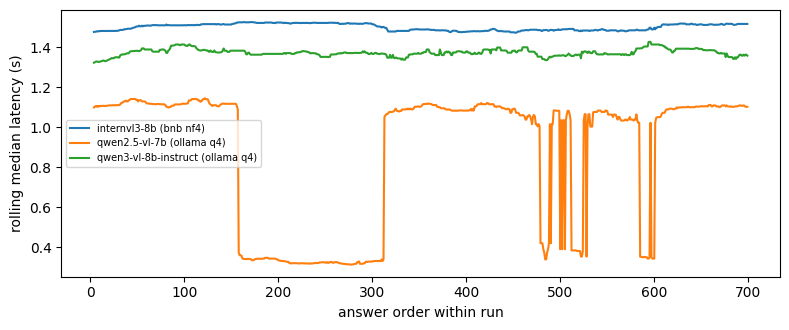

In [5]:
lat = []
for m, g in P.groupby("model"):
    x = g.latency_s.values; warm = x[5:]
    row = {"model": m, "n": len(x), "mean_s": x.mean(), "median_s": np.median(x), "p95_s": np.percentile(x, 95), "mean_without_first_5": warm.mean(), "median_without_first_5": np.median(warm)}
    for ds, sub in (("pope_original", g[(g.set == "pope") & (g.variant == "original")]), ("vqa", g[g.set == "vqa"])): row[f"median_s_{ds}"] = sub.latency_s.median()
    lat.append(row)
lt = pd.DataFrame(lat).round(3); lt.to_csv(OUT / "latency_median_p95.csv", index=False); display(lt)
fig, ax = plt.subplots(figsize=(8, 3.4))
for m, g in P.groupby("model"): ax.plot(np.arange(len(g)), g.latency_s.rolling(25, min_periods=5).median().values, label=m)
ax.set_xlabel("answer order within run"); ax.set_ylabel("rolling median latency (s)"); ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(OUT / "latency_drift.png", dpi=150); plt.show()

## 4. Limits to carry into the report
- 300 POPE questions come from a limited set of images, so questions are not fully independent (see the image-cluster bootstrap).
- The systems differ in runtime, quantisation and image tiling (GGUF Q4 through Ollama against NF4 through transformers), so differences cannot be attributed to the model alone.
- Latency drifts within a run and differs by subset (see the figure and the per-subset medians). The median and the 95th percentile are more reliable than the mean, but the gap between models depends on the subset.
- Hardware-specific numbers (latency, energy) only apply to the machine recorded in `environment.json`.